<a href="https://colab.research.google.com/github/shrutikushwaha2110-ux/Facial-Expression-Recognition-CNN/blob/main/notebooks/03_ablation_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        print(os.path.join(root, file))

/content/fer2013_preprocessed.npz.zip
/content/X_test.npy
/content/y_test.npy
/content/y_val.npy
/content/X_train.npy
/content/X_val.npy
/content/y_train.npy
/content/.config/default_configs.db
/content/.config/.last_update_check.json
/content/.config/.last_survey_prompt.yaml
/content/.config/config_sentinel
/content/.config/active_config
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/gce
/content/.config/.last_opt_in_prompt.yaml
/content/.config/configurations/config_default
/content/.config/logs/2026.10.21/13.27.51.774504.log
/content/.config/logs/2026.10.21/13.28.05.116687.log
/content/.config/logs/2026.10.21/13.27.28.750982.log
/content/.config/logs/2026.10.21/13.28.04.564766.log
/content/.config/logs/2026.10.21/13.27.58.650478.log
/content/.config/logs/2026.10.21/13.27.57.480371.log
/content/sample_data/README.md
/content/sample_data/anscombe.json
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_sma

In [ ]:
import numpy as np

X_train = np.load("/content/X_train.npy")
y_train = np.load("/content/y_train.npy")

X_val = np.load("/content/X_val.npy")
y_val = np.load("/content/y_val.npy")

X_test = np.load("/content/X_test.npy")
y_test = np.load("/content/y_test.npy")

print("Dataset loaded successfully!")

print("\nDataset Shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Dataset loaded successfully!

Dataset Shapes:
X_train: (22949, 48, 48, 1)
y_train: (22949,)
X_val: (5749, 48, 48, 1)
y_val: (5749,)
X_test: (7178, 48, 48, 1)
y_test: (7178,)


In [ ]:
print("Data type:", X_train.dtype)
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

print("Unique emotion labels:", np.unique(y_train))

Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Unique emotion labels: [0 1 2 3 4 5 6]


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def build_cnn(num_blocks):

    model = keras.Sequential()
    model.add(keras.Input(shape=(48, 48, 1)))

    filters = [32, 64, 128, 256]

    for i in range(num_blocks):

        model.add(layers.Conv2D(
            filters[i],
            (3, 3),
            activation='relu',
            padding='same'
        ))

        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())

    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.5))

    model.add(layers.Dense(7, activation='softmax'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

print("CNN builder created successfully!")

CNN builder created successfully!


In [ ]:
model_2 = build_cnn(num_blocks=2)

model_2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,199,879 (4.58 MB)

 Trainable params: 1,199,687 (4.58 MB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
early_stopping_2 = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_2 = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_2 = model_2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping_2, reduce_lr_2],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 19s 29ms/step - accuracy: 0.2696 - loss: 1.9115 - val_accuracy: 0.2166 - val_loss: 2.9226 - learning_rate: 0.0010
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.2906 - loss: 1.7108 - val_accuracy: 0.3321 - val_loss: 1.6547 - learning_rate: 0.0010
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.2935 - loss: 1.6763 - val_accuracy: 0.3493 - val_loss: 1.6466 - learning_rate: 0.0010
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.3035 - loss: 1.6451 - val_accuracy: 0.2623 - val_loss: 1.7499 - learning_rate: 0.0010
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.3127 - loss: 1.6300 - val_accuracy: 0.3865 - val_loss: 1.5789 - learning_rate: 0.0010
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.3290 - loss: 1.6035 - val_accuracy: 0.3783 - val_loss: 1.5794 - learning_rate: 0.0010
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.3364 - loss: 1.5896

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

y_pred_2 = np.argmax(model_2.predict(X_val), axis=1)

accuracy_2 = accuracy_score(y_val, y_pred_2)

macro_f1_2 = f1_score(
    y_val,
    y_pred_2,
    average='macro'
)

print("2-Block CNN Results")
print("-------------------")
print("Validation Accuracy:", round(accuracy_2 * 100, 2), "%")
print("Macro F1 Score:", round(macro_f1_2, 4))

180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
2-Block CNN Results
-------------------
Validation Accuracy: 44.72 %
Macro F1 Score: 0.3616


In [ ]:
model_2.save('/content/phase3_two_block_cnn.keras')

print("2-block CNN saved successfully!")

2-block CNN saved successfully!


In [ ]:
import pandas as pd

results = [
    {
        'Experiment': 'Baseline CNN',
        'Conv Blocks': 3,
        'Validation Accuracy': 0.5074,
        'Macro F1': 0.3933,
        'Best Validation Loss': 1.3150
    },
    {
        'Experiment': 'Two Block CNN',
        'Conv Blocks': 2,
        'Validation Accuracy': 0.4740,
        'Macro F1': 0.3577,
        'Best Validation Loss': 1.3836
    },
    {
        'Experiment': 'Four Block CNN',
        'Conv Blocks': 4,
        'Validation Accuracy': 0.4907,
        'Macro F1': 0.3979,
        'Best Validation Loss': None
    }
]

results_df = pd.DataFrame(results)

results_df.to_csv(
    '/content/phase3_depth_results.csv',
    index=False
)

print(results_df)

       Experiment  Conv Blocks  Validation Accuracy  Macro F1  \
0    Baseline CNN            3               0.5074    0.3933   
1   Two Block CNN            2               0.4740    0.3577   
2  Four Block CNN            4               0.4907    0.3979   

   Best Validation Loss  
0                1.3150  
1                1.3836  
2                   NaN  


In [ ]:
model_4 = build_cnn(num_blocks=4)

model_4.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 685,703 (2.62 MB)

 Trainable params: 684,743 (2.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
early_stopping_4 = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_4 = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

In [ ]:
history_4 = model_4.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping_4, reduce_lr_4],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 23s 36ms/step - accuracy: 0.2676 - loss: 1.8114 - val_accuracy: 0.1806 - val_loss: 3.0128 - learning_rate: 0.0010
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3374 - loss: 1.6363 - val_accuracy: 0.3966 - val_loss: 1.5283 - learning_rate: 0.0010
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.3843 - loss: 1.5342 - val_accuracy: 0.4168 - val_loss: 1.5100 - learning_rate: 0.0010
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.4203 - loss: 1.4518 - val_accuracy: 0.3780 - val_loss: 1.5933 - learning_rate: 0.0010
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.4486 - loss: 1.3900 - val_accuracy: 0.4324 - val_loss: 1.4440 - learning_rate: 0.0010
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.4772 - loss: 1.3255 - val_accuracy: 0.4700 - val_loss: 1.3789 - learning_rate: 0.0010
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.5134 - loss: 1

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

y_pred_4 = np.argmax(model_4.predict(X_val), axis=1)

accuracy_4 = accuracy_score(y_val, y_pred_4)

macro_f1_4 = f1_score(
    y_val,
    y_pred_4,
    average='macro'
)

print("4-Block CNN Results")
print("-------------------")
print("Validation Accuracy:", round(accuracy_4 * 100, 2), "%")
print("Macro F1 Score:", round(macro_f1_4, 4))

180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
4-Block CNN Results
-------------------
Validation Accuracy: 51.56 %
Macro F1 Score: 0.4299


In [ ]:
model_4.save('/content/phase3_four_block_cnn.keras')

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def build_cnn_bn(use_batch_norm=True):

    model = keras.Sequential()
    model.add(keras.Input(shape=(48, 48, 1)))

    filters = [32, 64, 128]

    for f in filters:

        model.add(
            layers.Conv2D(
                f,
                (3, 3),
                activation='relu',
                padding='same'
            )
        )

        if use_batch_norm:
            model.add(layers.BatchNormalization())

        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())

    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.5))

    model.add(layers.Dense(7, activation='softmax'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

print("Batch Normalization experiment builder created!")

Batch Normalization experiment builder created!


In [ ]:
model_bn_on = build_cnn_bn(use_batch_norm=True)

model_bn_on.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
early_stopping_bn_on = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_bn_on = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_bn_on = model_bn_on.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping_bn_on, reduce_lr_bn_on],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.2367 - loss: 1.8930 - val_accuracy: 0.1802 - val_loss: 2.7115 - learning_rate: 0.0010
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.2664 - loss: 1.7457 - val_accuracy: 0.3225 - val_loss: 1.6303 - learning_rate: 0.0010
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3018 - loss: 1.6855 - val_accuracy: 0.3136 - val_loss: 1.6847 - learning_rate: 0.0010
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3250 - loss: 1.6263 - val_accuracy: 0.3594 - val_loss: 1.5409 - learning_rate: 0.0010
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3408 - loss: 1.5922 - val_accuracy: 0.3074 - val_loss: 1.6557 - learning_rate: 0.0010
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3469 - loss: 1.5722 - val_accuracy: 0.3755 - val_loss: 1.5717 - learning_rate: 0.0010
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3615 - loss: 1.52

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

y_pred_bn_on = np.argmax(
    model_bn_on.predict(X_val),
    axis=1
)

accuracy_bn_on = accuracy_score(y_val, y_pred_bn_on)

macro_f1_bn_on = f1_score(
    y_val,
    y_pred_bn_on,
    average='macro'
)

print("Batch Normalization ON Results")
print("-------------------------------")
print(f"Validation Accuracy: {accuracy_bn_on * 100:.2f}%")
print(f"Macro F1 Score: {macro_f1_bn_on:.4f}")

180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Batch Normalization ON Results
-------------------------------
Validation Accuracy: 48.88%
Macro F1 Score: 0.3944


In [ ]:
model_bn_on.save('/content/phase3_batchnorm_on.keras')

In [ ]:
model_bn_off = build_cnn_bn(use_batch_norm=False)

model_bn_off.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,527 (2.61 MB)

 Trainable params: 683,527 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping_bn_off = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_bn_off = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_bn_off = model_bn_off.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping_bn_off, reduce_lr_bn_off],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.2703 - loss: 1.7820 - val_accuracy: 0.3740 - val_loss: 1.6353 - learning_rate: 0.0010
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3690 - loss: 1.6051 - val_accuracy: 0.4305 - val_loss: 1.4768 - learning_rate: 0.0010
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4207 - loss: 1.4913 - val_accuracy: 0.4780 - val_loss: 1.3784 - learning_rate: 0.0010
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4584 - loss: 1.4042 - val_accuracy: 0.5077 - val_loss: 1.3174 - learning_rate: 0.0010
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.4893 - loss: 1.3337 - val_accuracy: 0.5234 - val_loss: 1.2752 - learning_rate: 0.0010
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.5123 - loss: 1.2694 - val_accuracy: 0.5352 - val_loss: 1.2306 - learning_rate: 0.0010
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5361 - loss: 1.2246 

In [ ]:
y_pred_bn_off = np.argmax(
    model_bn_off.predict(X_val),
    axis=1
)

accuracy_bn_off = accuracy_score(y_val, y_pred_bn_off)

macro_f1_bn_off = f1_score(
    y_val,
    y_pred_bn_off,
    average='macro'
)

print("Batch Normalization OFF Results")
print("--------------------------------")
print(f"Validation Accuracy: {accuracy_bn_off * 100:.2f}%")
print(f"Macro F1 Score: {macro_f1_bn_off:.4f}")

180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
Batch Normalization OFF Results
--------------------------------
Validation Accuracy: 56.06%
Macro F1 Score: 0.4630


In [ ]:
model_bn_off.save('/content/phase3_batchnorm_off.keras')

In [ ]:
print("BATCH NORMALIZATION COMPARISON")
print("--------------------------------")

print(f"ON  - Accuracy: {accuracy_bn_on * 100:.2f}%")
print(f"ON  - Macro F1: {macro_f1_bn_on:.4f}")

print()

print(f"OFF - Accuracy: {accuracy_bn_off * 100:.2f}%")
print(f"OFF - Macro F1: {macro_f1_bn_off:.4f}")

BATCH NORMALIZATION COMPARISON
--------------------------------
ON  - Accuracy: 48.88%
ON  - Macro F1: 0.3944

OFF - Accuracy: 56.06%
OFF - Macro F1: 0.4630


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def build_cnn_dropout(dropout_rate):

    model = keras.Sequential()

    model.add(keras.Input(shape=(48, 48, 1)))

    filters = [32, 64, 128]

    for f in filters:

        model.add(
            layers.Conv2D(
                f,
                (3, 3),
                activation='relu',
                padding='same'
            )
        )

        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())

    model.add(layers.Dense(128, activation='relu'))

    model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(7, activation='softmax'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

print("Dropout experiment builder created!")

Dropout experiment builder created!


In [ ]:
model_drop_03 = build_cnn_dropout(0.3)

early_03 = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_03 = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_drop_03 = model_drop_03.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_03, lr_03],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 14s 25ms/step - accuracy: 0.2921 - loss: 1.7965 - val_accuracy: 0.2733 - val_loss: 1.8140 - learning_rate: 0.0010
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3937 - loss: 1.5403 - val_accuracy: 0.4432 - val_loss: 1.4485 - learning_rate: 0.0010
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4249 - loss: 1.4501 - val_accuracy: 0.4312 - val_loss: 1.5258 - learning_rate: 0.0010
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.4485 - loss: 1.3809 - val_accuracy: 0.4881 - val_loss: 1.3670 - learning_rate: 0.0010
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4791 - loss: 1.3144 - val_accuracy: 0.4865 - val_loss: 1.3413 - learning_rate: 0.0010
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5005 - loss: 1.2682 - val_accuracy: 0.4723 - val_loss: 1.3960 - learning_rate: 0.0010
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5362 - loss: 1.1812

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

pred_03 = np.argmax(model_drop_03.predict(X_val), axis=1)

acc_03 = accuracy_score(y_val, pred_03)
f1_03 = f1_score(y_val, pred_03, average='macro')

print("Dropout 0.3 Results")
print("Accuracy:", round(acc_03 * 100, 2), "%")
print("Macro F1:", round(f1_03, 4))

model_drop_03.save('/content/phase3_dropout_03.keras')

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Dropout 0.3 Results
Accuracy: 54.22 %
Macro F1: 0.4473


In [ ]:
model_drop_05 = build_cnn_dropout(0.5)

early_05 = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_05 = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_drop_05 = model_drop_05.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_05, lr_05],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.2602 - loss: 1.8650 - val_accuracy: 0.3028 - val_loss: 1.7797 - learning_rate: 0.0010
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3052 - loss: 1.6812 - val_accuracy: 0.3952 - val_loss: 1.5335 - learning_rate: 0.0010
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3285 - loss: 1.6260 - val_accuracy: 0.3903 - val_loss: 1.6135 - learning_rate: 0.0010
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3486 - loss: 1.5838 - val_accuracy: 0.3823 - val_loss: 1.5990 - learning_rate: 0.0010
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3832 - loss: 1.5080 - val_accuracy: 0.3594 - val_loss: 1.6003 - learning_rate: 5.0000e-04
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3984 - loss: 1.4712 - val_accuracy: 0.4618 - val_loss: 1.4076 - learning_rate: 5.0000e-04
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4042 - l

In [ ]:
pred_05 = np.argmax(model_drop_05.predict(X_val), axis=1)

acc_05 = accuracy_score(y_val, pred_05)
f1_05 = f1_score(y_val, pred_05, average='macro')

print("Dropout 0.5 Results")
print("Accuracy:", round(acc_05 * 100, 2), "%")
print("Macro F1:", round(f1_05, 4))

model_drop_05.save('/content/phase3_dropout_05.keras')

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Dropout 0.5 Results
Accuracy: 50.13 %
Macro F1: 0.4102


In [ ]:
model_drop_07 = build_cnn_dropout(0.7)

early_07 = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_07 = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_drop_07 = model_drop_07.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_07, lr_07],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.2453 - loss: 1.9089 - val_accuracy: 0.2373 - val_loss: 2.0497 - learning_rate: 0.0010
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.2505 - loss: 1.7884 - val_accuracy: 0.2517 - val_loss: 1.7264 - learning_rate: 0.0010
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.2688 - loss: 1.7324 - val_accuracy: 0.3004 - val_loss: 1.6377 - learning_rate: 0.0010
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.2917 - loss: 1.6939 - val_accuracy: 0.3599 - val_loss: 1.6927 - learning_rate: 0.0010
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.2989 - loss: 1.6705 - val_accuracy: 0.3254 - val_loss: 1.6734 - learning_rate: 0.0010
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3125 - loss: 1.6383 - val_accuracy: 0.3719 - val_loss: 1.5707 - learning_rate: 5.0000e-04
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3273 - loss: 1

In [ ]:
pred_07 = np.argmax(
    model_drop_07.predict(X_val),
    axis=1
)

acc_07 = accuracy_score(y_val, pred_07)

f1_07 = f1_score(
    y_val,
    pred_07,
    average='macro'
)

print("Dropout 0.7 Results")
print("Accuracy:", round(acc_07 * 100, 2), "%")
print("Macro F1:", round(f1_07, 4))

model_drop_07.save('/content/phase3_dropout_07.keras')

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Dropout 0.7 Results
Accuracy: 44.11 %
Macro F1: 0.321


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def build_cnn_optimizer(optimizer):

    model = keras.Sequential()

    model.add(keras.Input(shape=(48, 48, 1)))

    filters = [32, 64, 128]

    for f in filters:

        model.add(
            layers.Conv2D(
                f,
                (3, 3),
                activation='relu',
                padding='same'
            )
        )

        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())

    model.add(layers.Dense(128, activation='relu'))

    model.add(layers.Dropout(0.3))

    model.add(layers.Dense(7, activation='softmax'))

    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

print("Optimizer experiment builder created!")

Optimizer experiment builder created!


In [ ]:
model_adam = build_cnn_optimizer(
    keras.optimizers.Adam(learning_rate=0.001)
)

model_adam.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_21 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
early_adam = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_adam = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_adam = model_adam.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_adam, lr_adam],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.3007 - loss: 1.7879 - val_accuracy: 0.2921 - val_loss: 1.7329 - learning_rate: 0.0010
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.3922 - loss: 1.5290 - val_accuracy: 0.3719 - val_loss: 1.5904 - learning_rate: 0.0010
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.4455 - loss: 1.4160 - val_accuracy: 0.4898 - val_loss: 1.3330 - learning_rate: 0.0010
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4834 - loss: 1.3292 - val_accuracy: 0.5093 - val_loss: 1.3065 - learning_rate: 0.0010
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5142 - loss: 1.2593 - val_accuracy: 0.4942 - val_loss: 1.3645 - learning_rate: 0.0010
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.5394 - loss: 1.1869 - val_accuracy: 0.4736 - val_loss: 1.3600 - learning_rate: 0.0010
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.5852 - loss: 1.0

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

pred_adam = np.argmax(
    model_adam.predict(X_val),
    axis=1
)

acc_adam = accuracy_score(y_val, pred_adam)

f1_adam = f1_score(
    y_val,
    pred_adam,
    average='macro'
)

print("Adam Results")
print("Accuracy:", round(acc_adam * 100, 2), "%")
print("Macro F1:", round(f1_adam, 4))

model_adam.save('/content/phase3_optimizer_adam.keras')

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Adam Results
Accuracy: 53.91 %
Macro F1: 0.4404


In [ ]:
model_sgd = build_cnn_optimizer(
    keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    )
)

model_sgd.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
early_sgd = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_sgd = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_sgd = model_sgd.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_sgd, lr_sgd],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.2690 - loss: 1.8024 - val_accuracy: 0.3241 - val_loss: 1.7090 - learning_rate: 0.0100
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3429 - loss: 1.6368 - val_accuracy: 0.3441 - val_loss: 1.6395 - learning_rate: 0.0100
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.3920 - loss: 1.5413 - val_accuracy: 0.4472 - val_loss: 1.4456 - learning_rate: 0.0100
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4238 - loss: 1.4656 - val_accuracy: 0.3688 - val_loss: 1.6114 - learning_rate: 0.0100
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4495 - loss: 1.4019 - val_accuracy: 0.4058 - val_loss: 1.4728 - learning_rate: 0.0100
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5015 - loss: 1.2797 - val_accuracy: 0.4853 - val_loss: 1.3334 - learning_rate: 0.0050
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5289 - loss: 1.208

In [ ]:
pred_sgd = np.argmax(
    model_sgd.predict(X_val),
    axis=1
)

acc_sgd = accuracy_score(y_val, pred_sgd)

f1_sgd = f1_score(
    y_val,
    pred_sgd,
    average='macro'
)

print("SGD with Momentum Results")
print("--------------------------")
print("Accuracy:", round(acc_sgd * 100, 2), "%")
print("Macro F1:", round(f1_sgd, 4))

model_sgd.save('/content/phase3_optimizer_sgd.keras')

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
SGD with Momentum Results
--------------------------
Accuracy: 52.2 %
Macro F1: 0.4582


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.05)
])

print("Data augmentation created successfully!")

Data augmentation created successfully!


In [ ]:
def build_cnn_augmentation(use_augmentation=False):

    model = keras.Sequential()

    model.add(keras.Input(shape=(48, 48, 1)))

    if use_augmentation:
        model.add(data_augmentation)

    filters = [32, 64, 128]

    for f in filters:

        model.add(
            layers.Conv2D(
                f,
                (3, 3),
                activation='relu',
                padding='same'
            )
        )

        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())

    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.3))

    model.add(layers.Dense(7, activation='softmax'))

    model.compile(
        optimizer=keras.optimizers.SGD(
            learning_rate=0.01,
            momentum=0.9
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

print("Augmentation CNN builder created!")

Augmentation CNN builder created!


In [ ]:
model_no_aug = build_cnn_augmentation(
    use_augmentation=False
)

early_no_aug = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_no_aug = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_no_aug = model_no_aug.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_no_aug, lr_no_aug],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.2841 - loss: 1.7679 - val_accuracy: 0.3284 - val_loss: 1.7295 - learning_rate: 0.0100
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3679 - loss: 1.5991 - val_accuracy: 0.4202 - val_loss: 1.5104 - learning_rate: 0.0100
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4117 - loss: 1.5045 - val_accuracy: 0.3879 - val_loss: 1.5754 - learning_rate: 0.0100
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4397 - loss: 1.4404 - val_accuracy: 0.3942 - val_loss: 1.5247 - learning_rate: 0.0100
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4868 - loss: 1.3237 - val_accuracy: 0.4550 - val_loss: 1.4133 - learning_rate: 0.0050
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.5115 - loss: 1.2574 - val_accuracy: 0.4730 - val_loss: 1.3994 - learning_rate: 0.0050
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.5291 - loss: 1.213

In [ ]:
pred_no_aug = np.argmax(
    model_no_aug.predict(X_val),
    axis=1
)

acc_no_aug = accuracy_score(y_val, pred_no_aug)

f1_no_aug = f1_score(
    y_val,
    pred_no_aug,
    average='macro'
)

print("WITHOUT Augmentation")
print("Accuracy:", round(acc_no_aug * 100, 2), "%")
print("Macro F1:", round(f1_no_aug, 4))

180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
WITHOUT Augmentation
Accuracy: 51.66 %
Macro F1: 0.4592


In [ ]:
model_no_aug.save('/content/phase3_without_augmentation.keras')

In [ ]:
model_with_aug = build_cnn_augmentation(
    use_augmentation=True
)

model_with_aug.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_9 (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
early_with_aug = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_with_aug = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_with_aug = model_with_aug.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_with_aug, lr_with_aug],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.2640 - loss: 1.8162 - val_accuracy: 0.3187 - val_loss: 1.6991 - learning_rate: 0.0100
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.3024 - loss: 1.7158 - val_accuracy: 0.3644 - val_loss: 1.6330 - learning_rate: 0.0100
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.3339 - loss: 1.6537 - val_accuracy: 0.3460 - val_loss: 1.6708 - learning_rate: 0.0100
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.3613 - loss: 1.6046 - val_accuracy: 0.4117 - val_loss: 1.4958 - learning_rate: 0.0100
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.3793 - loss: 1.5733 - val_accuracy: 0.3091 - val_loss: 1.7136 - learning_rate: 0.0100
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.3795 - loss: 1.5581 - val_accuracy: 0.4202 - val_loss: 1.4997 - learning_rate: 0.0100
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.4225 - loss: 1

In [ ]:
pred_with_aug = np.argmax(
    model_with_aug.predict(X_val),
    axis=1
)

acc_with_aug = accuracy_score(
    y_val,
    pred_with_aug
)

f1_with_aug = f1_score(
    y_val,
    pred_with_aug,
    average='macro'
)

print("WITH Augmentation Results")
print("--------------------------")
print("Accuracy:", round(acc_with_aug * 100, 2), "%")
print("Macro F1:", round(f1_with_aug, 4))

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
WITH Augmentation Results
--------------------------
Accuracy: 55.07 %
Macro F1: 0.4579


In [ ]:
model_with_aug.save(
    '/content/phase3_with_augmentation.keras'
)

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weight_dict = dict(
    zip(classes, class_weights)
)

print("Class Weights:")
for cls, weight in class_weight_dict.items():
    print(f"Class {cls}: {weight:.4f}")

Class Weights:
Class 0: 1.0274
Class 1: 9.4479
Class 2: 0.9989
Class 3: 0.5679
Class 4: 0.8500
Class 5: 1.2989
Class 6: 0.8248


In [ ]:
model_class_weights = build_cnn_augmentation(
    use_augmentation=True
)

model_class_weights.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_9 (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
early_cw = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_cw = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_cw = model_class_weights.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_cw, lr_cw],
    verbose=1
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.1403 - loss: 1.9918 - val_accuracy: 0.0814 - val_loss: 1.9828 - learning_rate: 0.0100
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.0759 - loss: 1.9470 - val_accuracy: 0.1492 - val_loss: 1.9406 - learning_rate: 0.0100
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.0983 - loss: 1.9464 - val_accuracy: 0.0484 - val_loss: 1.9467 - learning_rate: 0.0100
Epoch 4/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.1351 - loss: 1.9384 - val_accuracy: 0.1842 - val_loss: 1.9277 - learning_rate: 0.0100
Epoch 5/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.1520 - loss: 1.9221 - val_accuracy: 0.1978 - val_loss: 1.8793 - learning_rate: 0.0100
Epoch 6/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.1041 - loss: 1.9365 - val_accuracy: 0.1409 - val_loss: 1.9387 - learning_rate: 0.0100
Epoch 7/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.1822 - loss: 1.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

pred_cw = np.argmax(
    model_class_weights.predict(X_val),
    axis=1
)

acc_cw = accuracy_score(y_val, pred_cw)

f1_cw = f1_score(
    y_val,
    pred_cw,
    average='macro'
)

print("CLASS WEIGHTS RESULTS")
print("---------------------")
print("Accuracy:", round(acc_cw * 100, 2), "%")
print("Macro F1:", round(f1_cw, 4))

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
CLASS WEIGHTS RESULTS
---------------------
Accuracy: 31.22 %
Macro F1: 0.1938


In [ ]:
model_class_weights.save(
    '/content/phase3_class_weights.keras'
)

In [ ]:
from collections import Counter

print("Original Training Class Distribution:")

for cls, count in sorted(Counter(y_train).items()):
    print(f"Class {cls}: {count}")

Original Training Class Distribution:
Class 0: 3191
Class 1: 347
Class 2: 3282
Class 3: 5773
Class 4: 3857
Class 5: 2524
Class 6: 3975


In [ ]:
from imblearn.over_sampling import RandomOverSampler
import numpy as np

X_train_flat = X_train.reshape(len(X_train), -1)

ros = RandomOverSampler(
    random_state=42
)

X_resampled, y_resampled = ros.fit_resample(
    X_train_flat,
    y_train
)

X_train_over = X_resampled.reshape(
    -1, 48, 48, 1
).astype('float32')

y_train_over = y_resampled

print("Original training shape:", X_train.shape)
print("Oversampled training shape:", X_train_over.shape)

Original training shape: (22949, 48, 48, 1)
Oversampled training shape: (40411, 48, 48, 1)


In [ ]:
print("Oversampled Class Distribution:")

for cls, count in sorted(Counter(y_train_over).items()):
    print(f"Class {cls}: {count}")

Oversampled Class Distribution:
Class 0: 5773
Class 1: 5773
Class 2: 5773
Class 3: 5773
Class 4: 5773
Class 5: 5773
Class 6: 5773


In [ ]:
model_oversampling = build_cnn_augmentation(
    use_augmentation=True
)

model_oversampling.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_9 (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_36 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_35          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_38 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
early_over = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_over = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history_over = model_oversampling.fit(
    X_train_over,
    y_train_over,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_over, lr_over],
    verbose=1
)

Epoch 1/30
632/632 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.1946 - loss: 1.9174 - val_accuracy: 0.2221 - val_loss: 1.8513 - learning_rate: 0.0100
Epoch 2/30
632/632 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.2589 - loss: 1.8168 - val_accuracy: 0.2602 - val_loss: 1.8217 - learning_rate: 0.0100
Epoch 3/30
632/632 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.3109 - loss: 1.7274 - val_accuracy: 0.3014 - val_loss: 1.7144 - learning_rate: 0.0100
Epoch 4/30
632/632 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.3503 - loss: 1.6556 - val_accuracy: 0.4055 - val_loss: 1.5514 - learning_rate: 0.0100
Epoch 5/30
632/632 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.3807 - loss: 1.5884 - val_accuracy: 0.4253 - val_loss: 1.4831 - learning_rate: 0.0100
Epoch 6/30
632/632 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.4079 - loss: 1.5296 - val_accuracy: 0.4463 - val_loss: 1.4208 - learning_rate: 0.0100
Epoch 7/30
632/632 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.4346 - l

In [ ]:
pred_over = np.argmax(
    model_oversampling.predict(X_val),
    axis=1
)

acc_over = accuracy_score(
    y_val,
    pred_over
)

f1_over = f1_score(
    y_val,
    pred_over,
    average='macro'
)

print("OVERSAMPLING RESULTS")
print("--------------------")
print("Accuracy:", round(acc_over * 100, 2), "%")
print("Macro F1:", round(f1_over, 4))


180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
OVERSAMPLING RESULTS
--------------------
Accuracy: 58.55 %
Macro F1: 0.5635


In [ ]:
model_oversampling.save(
    '/content/phase3_oversampling.keras'
)

CLASSIFICATION REPORT - OVERSAMPLING
              precision    recall  f1-score   support

       Angry       0.45      0.51      0.48       797
     Disgust       0.50      0.60      0.54        89
        Fear       0.45      0.39      0.42       815
       Happy       0.81      0.80      0.80      1441
         Sad       0.53      0.43      0.48       972
    Surprise       0.71      0.69      0.70       646
     Neutral       0.48      0.59      0.53       989

    accuracy                           0.59      5749
   macro avg       0.56      0.57      0.56      5749
weighted avg       0.59      0.59      0.59      5749



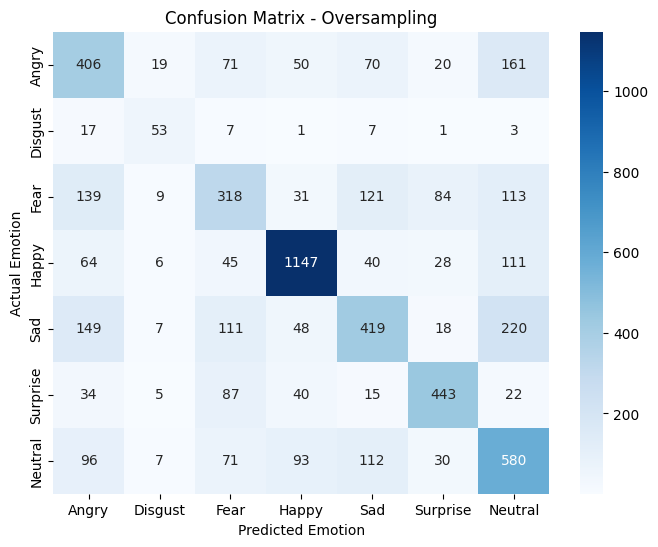

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("CLASSIFICATION REPORT - OVERSAMPLING")
print(classification_report(
    y_val,
    pred_over,
    target_names=[
        'Angry', 'Disgust', 'Fear', 'Happy',
        'Sad', 'Surprise', 'Neutral'
    ],
    zero_division=0
))

cm = confusion_matrix(y_val, pred_over)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[
        'Angry', 'Disgust', 'Fear', 'Happy',
        'Sad', 'Surprise', 'Neutral'
    ],
    yticklabels=[
        'Angry', 'Disgust', 'Fear', 'Happy',
        'Sad', 'Surprise', 'Neutral'
    ]
)
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Confusion Matrix - Oversampling")
plt.show()

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Build the final CNN with augmentation
final_model = build_cnn_augmentation(use_augmentation=True)

# Display architecture
final_model.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_9 (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_39 (MaxPooling2D) │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_40 (MaxPooling2D) │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_38          │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_41 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_13 (Flatten)            │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
final_model.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_final = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

lr_final = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

In [ ]:
history_final = final_model.fit(
    X_train_over,
    y_train_over,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_final, lr_final],
    verbose=1
)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Predict validation labels
final_predictions = np.argmax(
    final_model.predict(X_val),
    axis=1
)

# Calculate metrics
final_accuracy = accuracy_score(y_val, final_predictions)
final_macro_f1 = f1_score(
    y_val,
    final_predictions,
    average='macro'
)

print("FINAL MODEL RESULTS")
print("-------------------")
print("Accuracy:", round(final_accuracy * 100, 2), "%")
print("Macro F1:", round(final_macro_f1, 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    final_predictions,
    target_names=[
        'Angry', 'Disgust', 'Fear', 'Happy',
        'Sad', 'Surprise', 'Neutral'
    ],
    zero_division=0
))

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
FINAL MODEL RESULTS
-------------------
Accuracy: 56.44 %
Macro F1: 0.5477

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Angry       0.43      0.51      0.47       797
     Disgust       0.50      0.63      0.56        89
        Fear       0.37      0.40      0.38       815
       Happy       0.84      0.77      0.80      1441
         Sad       0.50      0.37      0.43       972
    Surprise       0.66      0.69      0.68       646
     Neutral       0.49      0.54      0.52       989

    accuracy                           0.56      5749
   macro avg       0.54      0.56      0.55      5749
weighted avg       0.57      0.56      0.57      5749



In [ ]:
import os
import json
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Create results folder
save_dir = "/content/phase3_final_results"
os.makedirs(save_dir, exist_ok=True)

# 1. Save final CNN model
final_model.save(f"{save_dir}/final_cnn_model.keras")

# 2. Save training history
history_data = {
    key: [float(v) for v in values]
    for key, values in history_final.history.items()
}

with open(f"{save_dir}/training_history.json", "w") as f:
    json.dump(history_data, f, indent=4)

# 3. Save evaluation metrics
results = {
    "validation_accuracy": float(final_accuracy),
    "macro_f1": float(final_macro_f1),
    "best_validation_accuracy": float(max(history_final.history["val_accuracy"])),
    "lowest_validation_loss": float(min(history_final.history["val_loss"]))
}

with open(f"{save_dir}/evaluation_results.json", "w") as f:
    json.dump(results, f, indent=4)

# 4. Save classification report
report = classification_report(
    y_val,
    final_predictions,
    target_names=[
        'Angry', 'Disgust', 'Fear', 'Happy',
        'Sad', 'Surprise', 'Neutral'
    ],
    output_dict=True,
    zero_division=0
)

with open(f"{save_dir}/classification_report.json", "w") as f:
    json.dump(report, f, indent=4)

# 5. Save confusion matrix
np.save(
    f"{save_dir}/confusion_matrix.npy",
    confusion_matrix(y_val, final_predictions)
)

print("All final Phase 3 results saved successfully!")
print("Location:", save_dir)
print(os.listdir(save_dir))

All final Phase 3 results saved successfully!
Location: /content/phase3_final_results
['confusion_matrix.npy', 'evaluation_results.json', 'training_history.json', 'final_cnn_model.keras', 'classification_report.json']


In [ ]:
import zipfile
import os

zip_path = "/content/fer2013_preprocessed.npz(1).zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Extracted files:")
print(os.listdir("/content"))

FileNotFoundError: [Errno 2] No such file or directory: '/content/fer2013_preprocessed.npz(1).zip'

In [ ]:
import os

print(os.listdir("/content"))

In [ ]:
import zipfile
import os

zip_path = "/content/fer2013_preprocessed.npz.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Extracted files:")
print(os.listdir("/content"))

In [ ]:
import numpy as np

X_train = np.load("/content/X_train.npy")
y_train = np.load("/content/y_train.npy")

X_val = np.load("/content/X_val.npy")
y_val = np.load("/content/y_val.npy")

X_test = np.load("/content/X_test.npy")
y_test = np.load("/content/y_test.npy")

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".keras", ".h5")):
            print(os.path.join(root, file))